# 02 — Modelling: fault detection and diagnosis

**Framing.** The maintenance team wants three things: is there a fault, which one, and as few wasted
visits as possible. Only 28 labelled events exist, labels are incomplete (work orders), and each
AHU has its own normal operating point. So the model has three layers, each doing one job:

1. **Physics features** per row (setpoint error, outdoor-air fraction, coil ΔT, fan power vs the affinity law).
2. **Normal-behaviour models**: gradient-boosted regressors fit on rows with no work order, one per
   signal for the whole fleet, AHU as a categorical input. They predict what valve, fan, mixed air,
   damper, CO2 and return air *should* be; the residual is the fault evidence. This is what lets the
   approach work on a new AHU and absorbs unit-to-unit differences.
3. **Classifier on trailing windows** (3 h and 12 h medians of residuals and physics features) that
   outputs P(normal) and P(each fault). Windows only look backwards, so the same code runs live.

A causal **alarm state machine** turns probabilities into alarms: open when the smoothed P(fault)
crosses a threshold, close only after a sustained quiet period, and type = the class with the highest
mean probability since the alarm opened (the type does not flicker).

Pure rules would need per-unit thresholds for 40 units; a pure classifier on raw signals would
learn unit identity, not faults. The hybrid keeps the physics explainable and lets the data set the thresholds.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ahu_fdd import pipeline as PL, features as F, events as E, experiments as X
from ahu_fdd.config import CLASSES, FAULTS, CODE_DIR

FIG = CODE_DIR.parent / "report" / "figures"
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

In [2]:
df, labels, log = PL.build_frame()
log[["issue", "building", "rows"]]

,issue,building,rows
0,clock shift (logger wrote UTC),B1,32153
1,duplicate export,B3,3439
2,"fan power in W, not kW",B3-AHU-04,6023
3,CO2 at 0 or 5000 ppm (sensor failure),B2-AHU-03,781
4,sat_c frozen (flatline),B2-AHU-08,2587
5,rat_c frozen (flatline),B1-AHU-07,2239
6,logging gap,B2,0


## 1. Normal-behaviour residuals (out of fold)

For train month *k*, the normal models are fit on every other month, minus a 2-day purge around
month *k* and minus any event that touches it. The test period uses models fit on all of January–June.

In [3]:
res = PL.residuals(df, labels)
w = PL.make_windows(df, res)
cols = F.feature_columns(w)
print(len(w), "steady running rows,", len(cols), "features")
clean = w[(w.split == "train") & (w.label == "normal") & ~w.near_event]
mae = {c: clean[c].abs().median() for c in F.RESID.values()}
by_class = w[w.split == "train"].groupby("label")[list(F.RESID.values())].median().round(2)
pd.Series(mae, name="median |residual| on normal rows").round(2).to_frame().T

1752625 steady running rows, 38 features


,r_valve,r_fan,r_mat,r_damper,r_co2,r_rat
median |residual| on normal rows,1.71,1.77,0.14,0.0,14.35,0.1


In [4]:
by_class  # median residual by true label: the faults move exactly the residuals the physics predicts

,r_valve,r_fan,r_mat,r_damper,r_co2,r_rat
label,,,,,,
chw_valve_stuck,15.55,22.23,0.35,0.0,-16.95,1.73
low_coil_capacity,16.64,0.37,0.02,0.0,4.29,0.04
normal,0.00,0.01,-0.00,0.0,1.03,0.00
oa_damper_stuck,-1.52,-0.04,-0.54,40.0,577.80,-0.00
sat_sensor_bias,-6.58,8.18,-0.01,0.0,43.65,-0.00


## 2. Validation scheme

* **Across time**: leave-one-month-out on Jan–Jun with a 2-day purge, so neither the normal models nor
  the classifier see the scored month. Rolling windows are trailing only.
* **Across events**: an event that spans two months is removed from training in both folds.
* **Fuzzy edges**: rows within 1 day of a labelled event that are not inside it are not used as
  "normal" for training (start/end are estimates).
* **Metric = the maintenance team's view**: events found, events found with the right type, median
  delay from start to first alarm, false alarms per AHU-month (an alarm run that touches no labelled
  event). Row-level accuracy is not reported: it is dominated by the 95% normal rows.

Post-processing is tuned on the out-of-fold probabilities with
`J = typed recall − 4 × false alarms per AHU-month`.

In [5]:
oof = PL.oof_probabilities(w, df, labels, cols)
tr = w[w.split == "train"]; keys = tr[["ahu_id", "timestamp"]]
AHU_MONTHS = 40 * 6

grid = []
for t_on in [0.6, 0.7, 0.8, 0.9]:
    for smooth in [12, 36]:
        for hold in [36, 144]:
            s, _, _ = E.score_events(keys, E.alarms(oof, keys, t_on, 0.3, smooth, hold), labels, AHU_MONTHS)
            grid.append(dict(t_on=t_on, smooth=smooth, hold=hold, **s, J=E.objective(s)))
grid = pd.DataFrame(grid).sort_values("J", ascending=False)
grid[["t_on", "smooth", "hold", "detected", "type_ok", "median_delay_h", "false_alarms", "fa_per_ahu_month", "J"]].round(3).head(8)

,t_on,smooth,hold,detected,type_ok,median_delay_h,false_alarms,fa_per_ahu_month,J
8,0.8,12,36,27,22,9.333,2,0.008,0.752
9,0.8,12,144,27,22,9.333,2,0.008,0.752
4,0.7,12,36,27,22,8.833,3,0.012,0.736
5,0.7,12,144,27,22,8.833,3,0.012,0.736
2,0.6,36,36,27,21,11.750,1,0.004,0.733
3,0.6,36,144,27,21,11.750,1,0.004,0.733
6,0.7,36,36,27,21,12.250,1,0.004,0.733
7,0.7,36,144,27,21,12.250,1,0.004,0.733


The top of the table is flat: thresholds 0.7 and 0.8 with 1-hour smoothing find the same 27 events with the same
22 correct types, and the hold time makes no difference. 0.8 has one false alarm fewer; longer smoothing
costs a type and about 3 hours of delay. We use `t_on=0.8, t_off=0.3, smooth=12, hold=144` (`pipeline.POST`).
The longer hold is chosen for production because it keeps one fault from re-opening several tickets.

## 3. Results (out of fold, Jan–Jun)

In [6]:
pred = E.alarms(oof, keys, **PL.POST)
summary, ev, al = E.score_events(keys, pred, labels, AHU_MONTHS)
pd.Series(summary).round(3)

events              28.000
detected            27.000
type_ok             22.000
recall               0.964
typed_recall         0.786
median_delay_h       9.333
alarms              33.000
false_alarms         2.000
fa_per_ahu_month     0.008
dtype: float64

In [7]:
ev["pred_type"] = ev.pred_type.fillna("missed")
pd.crosstab(ev.fault_type, ev.pred_type, margins=True)

pred_type,chw_valve_stuck,low_coil_capacity,missed,oa_damper_stuck,sat_sensor_bias,All
fault_type,,,,,,
chw_valve_stuck,7,0,0,0,1,8
low_coil_capacity,1,5,0,0,1,7
oa_damper_stuck,0,0,1,6,0,7
sat_sensor_bias,1,1,0,0,4,6
All,9,6,1,6,6,28


In [8]:
ev.groupby("fault_type").agg(events=("detected", "size"), detected=("detected", "sum"),
                             type_ok=("type_ok", "sum"), median_delay_h=("delay_h", "median")).round(1)

,events,detected,type_ok,median_delay_h
fault_type,,,,
chw_valve_stuck,8,8,7,2.0
low_coil_capacity,7,7,5,20.2
oa_damper_stuck,7,6,6,2.5
sat_sensor_bias,6,6,4,31.1


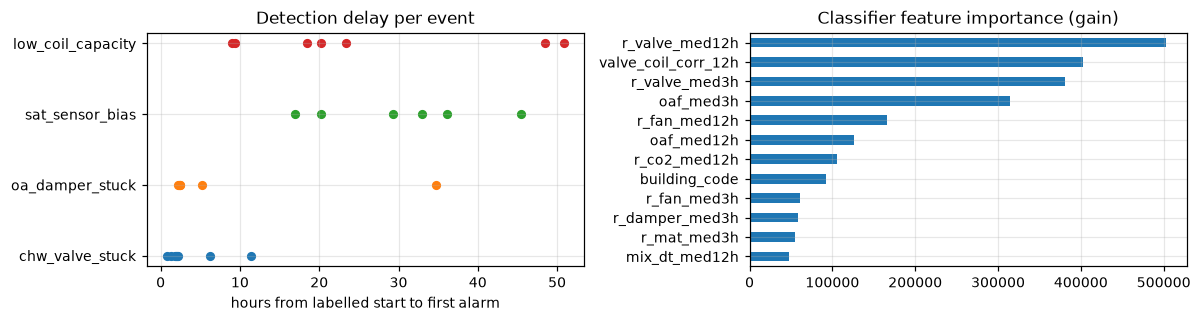

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for f in FAULTS:
    d = ev[(ev.fault_type == f) & ev.detected].delay_h
    ax[0].scatter(d, [f] * len(d), s=25)
ax[0].set_xlabel("hours from labelled start to first alarm"); ax[0].set_title("Detection delay per event")
imp = pd.Series(PL.fit_classifier(tr[cols], tr.label).booster_.feature_importance("gain"), index=cols)
imp.sort_values().tail(12).plot.barh(ax=ax[1]); ax[1].set_title("Classifier feature importance (gain)")
fig.tight_layout(); fig.savefig(FIG / "results.png", dpi=170)

## 4. Error analysis

In [10]:
ev[~ev.type_ok][["ahu_id", "fault_type", "start", "end", "detected", "delay_h", "pred_type"]]

,ahu_id,fault_type,start,end,detected,delay_h,pred_type
8,B1-AHU-05,low_coil_capacity,2025-03-03 16:20:00,2025-03-06 19:10:00,True,50.916667,chw_valve_stuck
9,B3-AHU-02,sat_sensor_bias,2025-03-06 03:05:00,2025-03-15 14:15:00,True,17.000000,chw_valve_stuck
11,B1-AHU-02,sat_sensor_bias,2025-03-26 11:45:00,2025-04-03 13:20:00,True,20.166667,low_coil_capacity
12,B3-AHU-02,low_coil_capacity,2025-03-29 16:50:00,2025-04-02 23:45:00,True,48.500000,sat_sensor_bias
14,B3-AHU-06,chw_valve_stuck,2025-04-13 20:25:00,2025-04-21 12:40:00,True,2.083333,sat_sensor_bias
17,B3-AHU-05,oa_damper_stuck,2025-04-20 16:25:00,2025-04-23 20:30:00,False,NaN,missed


Six events are missed or mistyped. **Half of them are on the three chronically saturated units**
(B1-AHU-05, B3-AHU-02, B3-AHU-09, see notebook 01), which hold only 3 of the 40 AHUs. Their valve already sits at 100%, so "low coil capacity" cannot show as
more valve opening; it shows as SAT rising, which is also what a stuck-closed valve or a biased sensor
do. With one or two events per such unit, the classifier cannot separate them. Fix: a separate
"saturated unit" mode with its own features (SAT rise vs CHW supply temperature and load), and asking
the client to check these units, which are probably undersized or permanently fouled.

**sat_sensor_bias vs low_coil_capacity** (B1-AHU-02) and **stuck valve vs sensor bias** (B3-AHU-06) are the other confusions. Both leave SAT on setpoint and move the
valve; the difference is in *how much cooling the air really gets*, which needs an independent
temperature (a discharge thermometer, or zone temperatures). In B2 the airflow station would help; we
do not have zone temperatures in this dataset.

**The missed damper fault (B3-AHU-05)** is in the mall, which has no CO2 sensor, so the damper command
does not react and the only evidence is a small change in mixed-air temperature over a short event.

**The only "false alarm" is an unlabelled fault.**

       ahu_id fault_type               start                 end  rows  true_alarm
10  B1-AHU-11      fault 2025-04-22 11:30:00 2025-05-02 18:30:00  1086       False
26  B3-AHU-06      fault 2025-02-15 12:10:00 2025-02-16 15:25:00   201       False


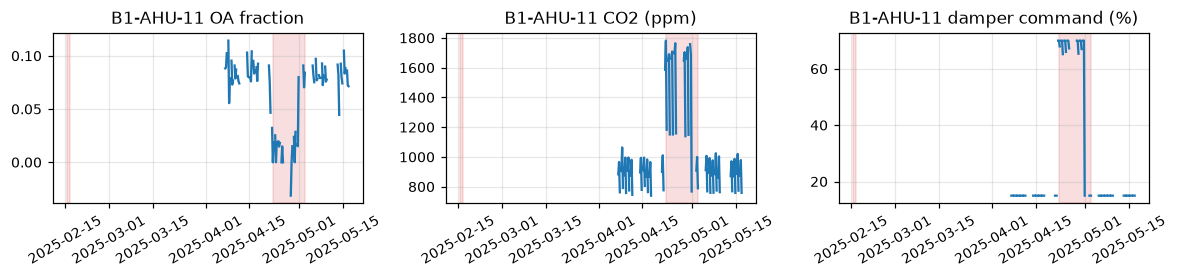

In [11]:
fa = al[~al.true_alarm]
print(fa)
x = w[(w.ahu_id == "B1-AHU-11") & w.timestamp.between("2025-04-07", "2025-05-19")]
fig, ax = plt.subplots(1, 3, figsize=(11, 2.6), sharex=True)
for a, c, t in zip(ax, ["oaf", "co2_ppm", "oa_damper_cmd_pct"], ["OA fraction", "CO2 (ppm)", "damper command (%)"]):
    s = x.set_index("timestamp")[c].resample("6h").median(); a.plot(s); a.set_title(f"B1-AHU-11 {t}")
    for r in fa.itertuples(): a.axvspan(r.start, r.end, color="tab:red", alpha=0.15)
    a.tick_params(axis="x", labelrotation=30)
fig.tight_layout(); fig.savefig(FIG / "unlabelled_damper.png", dpi=170)

B1-AHU-11, 22 Apr–5 May: outdoor-air fraction drops from 0.08 to 0.02, CO2 climbs by about 650 ppm, and
the controller opens the damper command from 15% to 70% with no effect. This is a stuck damper with
no work order, i.e. the labels are incomplete. Counting it as correct, the out-of-fold false alarm rate is zero.

## 5. New AHU and fewer sensors

* **New AHU**: hold out a quarter of the AHUs (stratified by building), fit the normal models and the
  classifier on the other units only, score the held-out ones, repeat for all four quarters. Run twice:
  (a) day one, no history at all; (b) after a 14-day listening period, where the normal models are
  refit with the new unit's first two healthy weeks (the classifier still never sees it, and the
  listening days are not scored).
* **Fewer sensors**: re-run the out-of-fold evaluation with the CO2 residuals removed for every AHU
  (and the airflow indicator off). Airflow already only enters through `flow_est`, which falls back to
  design airflow × fan speed, so CO2 is the sensor that matters.

In [12]:
exp = {"baseline": summary}
for name, drop in [("no CO2", ("co2",)), ("no CO2, no airflow", ("co2", "flow"))]:
    p, k = X.fewer_sensors(w, labels, drop)
    exp[name], _ = X.score(p, k, labels, AHU_MONTHS)
p, k = X.new_ahu(df, w, labels)
exp["new AHU, day one"], _ = X.score(p, k, labels, AHU_MONTHS)
p, k = X.new_ahu(df, w, labels, baseline_days=14)
exp["new AHU, after 14-day listening"], ev_new = X.score(p, k, labels, AHU_MONTHS * (1 - 14 / 181))
cmp = pd.DataFrame(exp).T[["detected", "type_ok", "median_delay_h", "false_alarms", "fa_per_ahu_month"]]
cmp.astype(float).round(3)

,detected,type_ok,median_delay_h,false_alarms,fa_per_ahu_month
baseline,27.0,22.0,9.333,2.0,0.008
no CO2,28.0,22.0,10.625,1.0,0.004
"no CO2, no airflow",27.0,21.0,10.083,2.0,0.008
"new AHU, day one",28.0,12.0,0.583,179.0,0.746
"new AHU, after 14-day listening",28.0,20.0,13.000,8.0,0.036


**Reading the table.** Losing CO2 costs almost nothing: the damper fault is still visible in the
mixed-air temperature balance (outdoor-air fraction), and CO2 mainly makes it faster to confirm. So a
building with fewer sensors gets the same model with those inputs missing (LightGBM handles NaN
natively), not a separate model.

A brand-new AHU is the real risk. On day one every fault is still found, but the normal models do not
know the unit's own operating point, so it raises about 0.75 false alarms per AHU-month, roughly 20
times the rate on known units, and half the types are wrong. Two weeks of listening (data collected,
nothing sent to technicians) brings false alarms back to about 0.04 per AHU-month and typing to about
70%. That is the onboarding rule used in Q3 and the recommendation in Q4.

In [13]:
json.dump({k: {m: float(v) for m, v in s.items()} for k, s in exp.items()},
          open(CODE_DIR / "outputs" / "experiments.json", "w"), indent=1)
ev_new.groupby("fault_type")[["detected", "type_ok"]].sum()

,detected,type_ok
fault_type,,
chw_valve_stuck,8,7
low_coil_capacity,7,3
oa_damper_stuck,7,7
sat_sensor_bias,6,3


## 6. Final model and predictions

Normal models and classifier refit on all of January–June, applied to July–August with the tuned
post-processing. `run()` repeats the steps above end to end.

In [14]:
sub, clf, _ = PL.run()
print(sub.fault_type.value_counts())
r = E.runs(sub, sub.fault_type)
r[(r.end - r.start) > pd.Timedelta("6h")]

fault_type
normal               682880
sat_sensor_bias       11302
oa_damper_stuck        7394
chw_valve_stuck        6584
low_coil_capacity      3834
Name: count, dtype: int64


,ahu_id,fault_type,start,end,rows
0,B1-AHU-01,chw_valve_stuck,2025-07-07 13:45:00,2025-07-15 11:00:00,2266
1,B1-AHU-03,low_coil_capacity,2025-07-09 08:55:00,2025-07-15 10:15:00,1741
2,B1-AHU-09,low_coil_capacity,2025-07-14 18:10:00,2025-07-21 16:15:00,1988
3,B1-AHU-12,low_coil_capacity,2025-07-22 10:15:00,2025-07-22 19:00:00,105
4,B1-AHU-12,sat_sensor_bias,2025-07-22 19:05:00,2025-08-08 10:05:00,4775
5,B1-AHU-16,chw_valve_stuck,2025-07-23 11:10:00,2025-07-29 08:55:00,1697
6,B2-AHU-07,oa_damper_stuck,2025-07-30 02:25:00,2025-08-05 21:05:00,1951
7,B2-AHU-12,oa_damper_stuck,2025-07-13 03:15:00,2025-07-25 04:30:00,3463
8,B3-AHU-01,oa_damper_stuck,2025-08-21 12:20:00,2025-08-28 10:05:00,1980
9,B3-AHU-03,sat_sensor_bias,2025-07-25 16:05:00,2025-07-29 11:20:00,1095


In [15]:
import subprocess
r = subprocess.run([sys.executable, str(CODE_DIR / "starter" / "validate_submission.py"),
                      str(CODE_DIR.parent / "predictions.csv")], capture_output=True, text=True)
print(r.stdout, r.stderr[-2000:])
assert r.returncode == 0

OK: 711994 rows, format is valid
 
